In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset

In [2]:
df = pd.read_csv("LogR.csv")

display(df.head())

print("Dataset shape:", df.shape)

df.info()

display(df.describe())

,Unnamed: 0,x1,x2,Output
0,0,34.623660,78.024693,0.0
1,1,30.286711,43.894998,0.0
2,2,35.847409,72.902198,0.0
3,3,60.182599,86.308552,1.0
4,4,79.032736,75.344376,1.0


Dataset shape: (100, 4)
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  100 non-null    int64  
 1   x1          100 non-null    float64
 2   x2          100 non-null    float64
 3   Output      100 non-null    float64
dtypes: float64(3), int64(1)
memory usage: 3.3 KB


,Unnamed: 0,x1,x2,Output
count,100.000000,100.000000,100.000000,100.000000
mean,49.500000,65.644274,66.221998,0.600000
std,29.011492,19.458222,18.582783,0.492366
min,0.000000,30.058822,30.603263,0.000000
25%,24.750000,50.919511,48.179205,0.000000
50%,49.500000,67.032988,67.682381,1.000000
75%,74.250000,80.212529,79.360605,1.000000
max,99.000000,99.827858,98.869436,1.000000


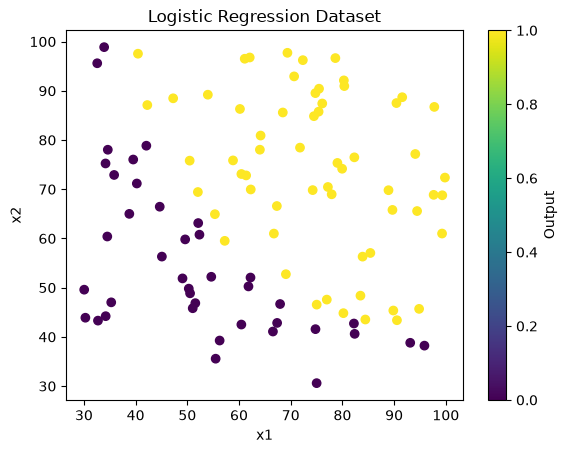

In [3]:
plt.scatter(df["x1"], df["x2"], c=df["Output"])
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Logistic Regression Dataset")
plt.colorbar(label="Output")
plt.show()

### Multivariate Logistic Regression

Multivariate Logistic Regression uses two or more input features to predict a binary output.

In our dataset, the input features are $x_1$ and $x_2$, and the target is Output (0 or 1).

Model equation:

$$
z=w_1x_1+w_2x_2+b
$$

Predicted probability:

$$
\hat y=\frac{1}{1+e^{-z}}
$$

Both features contribute to the prediction through their respective weights.

## Feature Scaling

Feature scaling brings input features to a similar scale.

We use standardization to give each feature a mean of 0 and a standard deviation of 1.

Formula:

$$
x_{scaled}=\frac{x-\mu}{\sigma}
$$

Here, $\mu$ is the mean and $\sigma$ is the standard deviation.

In [4]:
X = df[["x1", "x2"]].values
y = df["Output"].values

mean = np.mean(X, axis=0)
std = np.std(X, axis=0)

X_scaled = (X - mean) / std

print("X shape:", X_scaled.shape)
print("y shape:", y.shape)
print("Scaled mean:", np.mean(X_scaled, axis=0))
print("Scaled standard deviation:", np.std(X_scaled, axis=0))

X shape: (100, 2)
y shape: (100,)
Scaled mean: [-7.66053887e-17  1.14575016e-15]
Scaled standard deviation: [1. 1.]


### Sigmoid Function

The sigmoid function converts any real-valued number into a probability between 0 and 1.

Formula:

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

For Logistic Regression:

$$
z=w_1x_1+w_2x_2+b
$$

A probability greater than or equal to 0.5 is classified as class 1; otherwise, it is classified as class 0.

In [5]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


z = np.array([-10, -2, 0, 2, 10])
print("Sigmoid values:", sigmoid(z))

w = np.zeros(2)
b = 0

y_hat = sigmoid(np.dot(X_scaled, w) + b)

print("Initial weights:", w)
print("Initial bias:", b)
print("First 10 probabilities:", y_hat[:10])

Sigmoid values: [4.53978687e-05 1.19202922e-01 5.00000000e-01 8.80797078e-01
 9.99954602e-01]
Initial weights: [0. 0.]
Initial bias: 0
First 10 probabilities: [0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5]


### Cost Function

The cost function measures how far the predicted probabilities are from the actual outputs. Logistic Regression uses Binary Cross-Entropy (Log Loss).

Formula:

$$
J(w,b)=-\frac{1}{m}\sum_{i=1}^{m}
\left[y_i\log(\hat y_i)+(1-y_i)\log(1-\hat y_i)\right]
$$

Here, $m$ is the number of observations, $y_i$ is the actual output, and $\hat y_i$ is the predicted probability.

A lower cost indicates better predictions on the data being evaluated.

In [6]:
def cost_function(y, y_hat):
    m = len(y)
    epsilon = 1e-15

    y_hat = np.clip(y_hat, epsilon, 1 - epsilon)

    cost = -np.sum(
        y * np.log(y_hat) +
        (1 - y) * np.log(1 - y_hat)
    ) / m

    return cost


print("Initial Cost:", cost_function(y, y_hat))

Initial Cost: 0.6931471805599453


### Gradient Calculation

The gradient measures how the cost changes with respect to each weight and the bias. It helps us find the direction in which the parameters should be updated to reduce the cost.

Formulas:

$$
dw_j=\frac{1}{m}\sum_{i=1}^{m}(\hat y_i-y_i)x_{ij}
$$

$$
db=\frac{1}{m}\sum_{i=1}^{m}(\hat y_i-y_i)
$$

The gradients are calculated using the prediction errors.

In [7]:
def gradient(X, y, y_hat):
    m = len(y)
    error = y_hat - y

    dw = np.dot(X.T, error) / m
    db = np.sum(error) / m

    return dw, db


dw, db = gradient(X_scaled, y, y_hat)

print("dw:", dw)
print("db:", db)

dw: [-0.28122914 -0.25098615]
db: -0.1


## Gradient Descent

Gradient Descent repeatedly updates the weights and bias to minimize the cost function.

Update formulas:

$$
w_j=w_j-\alpha dw_j
$$

$$
b=b-\alpha db
$$

Here, $\alpha$ is the learning rate.

In [8]:
def train_model(X, y, alpha, iterations, reg_lambda=0):
    m = len(y)

    w = np.zeros(X.shape[1])
    b = 0

    cost_history = []

    for i in range(iterations):
        y_hat = sigmoid(np.dot(X, w) + b)

        dw, db = gradient(X, y, y_hat)

        dw = dw + (reg_lambda / m) * w

        w = w - alpha * dw
        b = b - alpha * db

        y_hat = sigmoid(np.dot(X, w) + b)

        cost = cost_function(y, y_hat)
        cost += (reg_lambda / (2 * m)) * np.sum(w ** 2)

        cost_history.append(cost)

    return w, b, cost_history

## Learning Rate

The learning rate controls the size of each Gradient Descent update.

We test different learning rates and compare their final costs to select a suitable value.

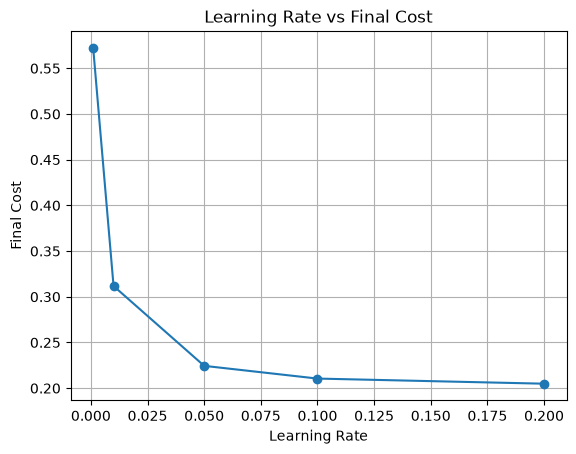

Best learning rate: 0.2
Lowest final cost: 0.20491060083873847


In [9]:
learning_rates = [0.001, 0.01, 0.05, 0.1, 0.2]
final_costs = []

for lr in learning_rates:
    _, _, history = train_model(
        X_scaled, y, lr, 1000
    )

    final_costs.append(history[-1])

plt.plot(learning_rates, final_costs, marker="o")
plt.xlabel("Learning Rate")
plt.ylabel("Final Cost")
plt.title("Learning Rate vs Final Cost")
plt.grid()
plt.show()

best_index = np.argmin(final_costs)
best_alpha = learning_rates[best_index]

print("Best learning rate:", best_alpha)
print("Lowest final cost:", final_costs[best_index])

In [10]:
w, b, cost_history = train_model(
    X_scaled, y, best_alpha, 10000
)

print("Final Weights:", w)
print("Final Bias:", b)
print("Final Cost:", cost_history[-1])

Final Weights: [3.99277605 3.72512532]
Final Bias: 1.7184440743267346
Final Cost: 0.2034977015902713


## Final Model Training

Using the selected learning rate, I train the final Logistic Regression model for 10,000 iterations and calculate the final weights, bias, and cost.

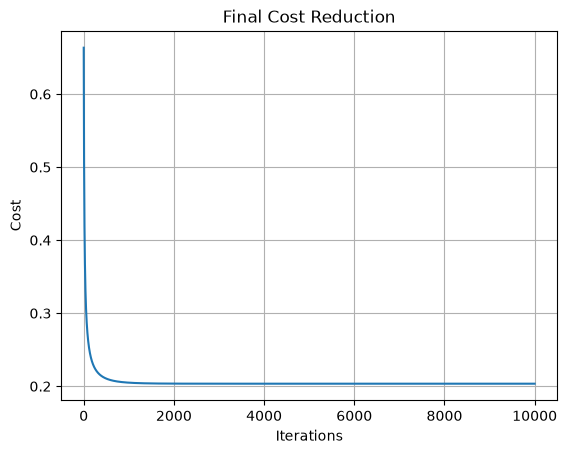

In [11]:
plt.plot(cost_history)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Final Cost Reduction")
plt.grid()
plt.show()

In [12]:
z = np.dot(X_scaled, w) + b
y_prob = sigmoid(z)

print("First 10 actual values:", y[:10])
print("First 10 probabilities:", y_prob[:10].round(4))

First 10 actual values: [0. 0. 0. 1. 1. 0. 1. 1. 1. 1.]
First 10 probabilities: [0.091  0.     0.0439 0.9904 0.9982 0.0108 0.999  0.4232 0.9997 0.7354]


### Prediction and Classification

Logistic Regression first predicts a probability and then converts it into a class using a threshold of 0.5.

$$
\hat y_{class}=
\begin{cases}
1 & \text{if } \hat y\geq 0.5\\
0 & \text{if } \hat y<0.5
\end{cases}
$$

The predicted class is compared with the actual output to evaluate the model.

In [13]:
y_pred = (y_prob >= 0.5).astype(int)

print("First 10 actual values:", y[:10])
print("First 10 predicted values:", y_pred[:10])

First 10 actual values: [0. 0. 0. 1. 1. 0. 1. 1. 1. 1.]
First 10 predicted values: [0 0 0 1 1 0 1 0 1 1]


In [14]:
prediction_table = pd.DataFrame({
    "x1": X[:, 0],
    "x2": X[:, 1],
    "Actual Output": y,
    "Predicted Probability": y_prob,
    "Predicted Output": y_pred
})

display(prediction_table.round(4))

,x1,x2,Actual Output,Predicted Probability,Predicted Output
0,34.6237,78.0247,0.0,0.0910,0
1,30.2867,43.8950,0.0,0.0000,0
2,35.8474,72.9022,0.0,0.0439,0
3,60.1826,86.3086,1.0,0.9904,1
4,79.0327,75.3444,1.0,0.9982,1
...,...,...,...,...,...
95,83.4892,48.3803,1.0,0.8586,1
96,42.2617,87.1039,1.0,0.7509,1
97,99.3150,68.7754,1.0,0.9999,1
98,55.3400,64.9319,1.0,0.3393,0


### Model Evaluation

We use the following metrics to evaluate the classification model.

Accuracy measures the proportion of correct predictions.

$$
Accuracy=\frac{TP+TN}{TP+TN+FP+FN}\times100
$$

Precision measures how many predicted positive cases are actually positive.

$$
Precision=\frac{TP}{TP+FP}
$$

Recall measures how many actual positive cases are correctly identified.

$$
Recall=\frac{TP}{TP+FN}
$$

The F1-score is the harmonic mean of Precision and Recall.

$$
F1=2\frac{Precision\times Recall}{Precision+Recall}
$$

In [15]:
correct = np.sum(y == y_pred)
accuracy = (correct / len(y)) * 100

print("Correct predictions:", correct)
print("Total predictions:", len(y))
print("Accuracy:", accuracy, "%")

Correct predictions: 89
Total predictions: 100
Accuracy: 89.0 %


### Confusion Matrix

A confusion matrix compares the actual classes with the predicted classes.

$$
\begin{bmatrix}
TN & FP\\
FN & TP
\end{bmatrix}
$$

- True Negative (TN): Actual 0, predicted 0.
- False Positive (FP): Actual 0, predicted 1.
- False Negative (FN): Actual 1, predicted 0.
- True Positive (TP): Actual 1, predicted 1.

It helps us understand the types of classification errors made by the model.

In [16]:
TP = np.sum((y == 1) & (y_pred == 1))
TN = np.sum((y == 0) & (y_pred == 0))
FP = np.sum((y == 0) & (y_pred == 1))
FN = np.sum((y == 1) & (y_pred == 0))

conf_matrix = np.array([
    [TN, FP],
    [FN, TP]
])

print("Confusion Matrix:")
print(conf_matrix)

Confusion Matrix:
[[34  6]
 [ 5 55]]


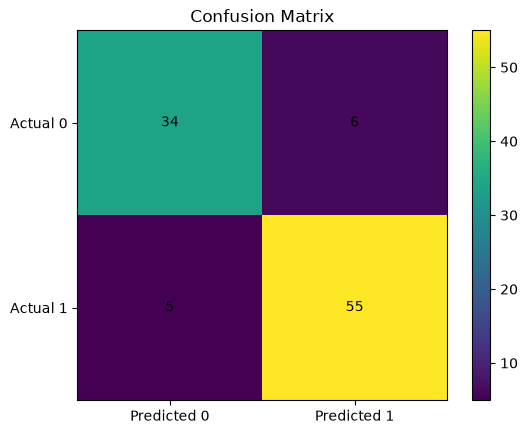

In [17]:
plt.imshow(conf_matrix)
plt.colorbar()

plt.xticks([0, 1], ["Predicted 0", "Predicted 1"])
plt.yticks([0, 1], ["Actual 0", "Actual 1"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, conf_matrix[i, j],
                 ha="center", va="center")

plt.title("Confusion Matrix")
plt.show()

In [18]:
precision = TP / (TP + FP) if TP + FP > 0 else 0
recall = TP / (TP + FN) if TP + FN > 0 else 0

f1 = (2 * precision * recall / (precision + recall)
      if precision + recall > 0 else 0)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: 0.9016393442622951
Recall: 0.9166666666666666
F1 Score: 0.9090909090909091


### Decision Boundary

The decision boundary separates the regions classified as class 0 and class 1.

At the boundary, the predicted probability is 0.5, so:

$$
w_1x_1+w_2x_2+b=0
$$

For two input features, this equation represents a straight line. The line is determined by the learned weights and bias.

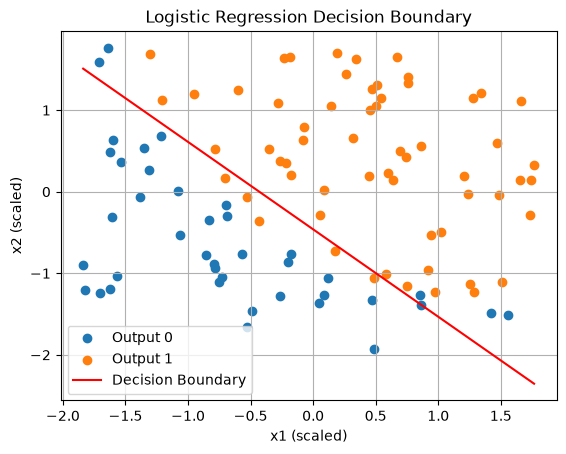

In [19]:
x1 = X_scaled[:, 0]
x2 = X_scaled[:, 1]

x1_values = np.linspace(x1.min(), x1.max(), 100)

if w[1] != 0:
    x2_values = -(w[0] * x1_values + b) / w[1]

    plt.scatter(x1[y == 0], x2[y == 0], label="Output 0")
    plt.scatter(x1[y == 1], x2[y == 1], label="Output 1")

    plt.plot(x1_values, x2_values, color="red",
             label="Decision Boundary")

    plt.xlabel("x1 (scaled)")
    plt.ylabel("x2 (scaled)")
    plt.title("Logistic Regression Decision Boundary")
    plt.legend()
    plt.grid()
    plt.show()

In [20]:
print("Final Weights:", w)
print("Final Bias:", b)
print("Final Cost:", cost_history[-1])
print("Training Accuracy:", accuracy, "%")
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Final Weights: [3.99277605 3.72512532]
Final Bias: 1.7184440743267346
Final Cost: 0.2034977015902713
Training Accuracy: 89.0 %
Precision: 0.9016393442622951
Recall: 0.9166666666666666
F1 Score: 0.9090909090909091


## Polynomial Logistic Regression with L2 Regularization

Logistic Regression using Polynomial Feature Mapping and L2 Regularization.

Polynomial features help the model learn a nonlinear decision boundary, while L2 Regularization helps control large weights.

In [21]:
def map_feature(X, degree=6):
    x1 = X[:, 0]
    x2 = X[:, 1]

    mapped_features = []

    for i in range(1, degree + 1):
        for j in range(i + 1):
            mapped_features.append(x1 ** (i - j) * x2 ** j)

    return np.column_stack(mapped_features)

In [22]:
X_poly = map_feature(X_scaled, degree=6)

print("Original features:", X_scaled.shape)
print("Polynomial features:", X_poly.shape)

Original features: (100, 2)
Polynomial features: (100, 27)


## L2 Regularization

L2 Regularization adds a penalty to the cost function to control large weights.

Regularized Cost:

$$
J(w,b)=J_{\text{BCE}}+
\frac{\lambda}{2m}\sum_{j=1}^{n}w_j^2
$$

Regularized Weight Gradient:

$$
dw=\frac{X^T(\hat y-y)}{m}+\frac{\lambda}{m}w
$$

Bias Gradient:

$$
db=\frac{1}{m}\sum_{i=1}^{m}(\hat y_i-y_i)
$$

The bias is not regularized. We use Gradient Descent to minimize the regularized cost.

In [23]:
w_poly, b_poly, cost_history_poly = train_model(
    X_poly,
    y,
    alpha=0.01,
    iterations=10000,
    reg_lambda=1
)

print("Final Weights:", w_poly)
print("Final Bias:", b_poly)
print("Final Cost:", cost_history_poly[-1])

Final Weights: [ 1.2065469   0.96691333  0.0904941  -0.93108328  0.24647462  0.81200921
  0.21548571  0.50245265  0.59977879 -0.11802898 -0.41394491  0.21458346
 -0.57686232  0.08218001  0.70362693  0.22976258  0.06157596  0.25620462
  0.15649579  0.84999262 -0.41969095  0.01883869 -0.13942859 -0.00127487
 -0.12514359 -0.03852875 -0.46804458]
Final Bias: 1.7851623134602872
Final Cost: 0.1302998968264627


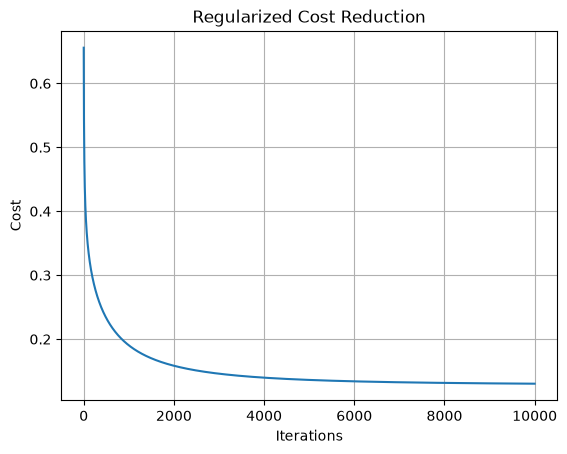

In [24]:
plt.plot(cost_history_poly)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Regularized Cost Reduction")
plt.grid()
plt.show()

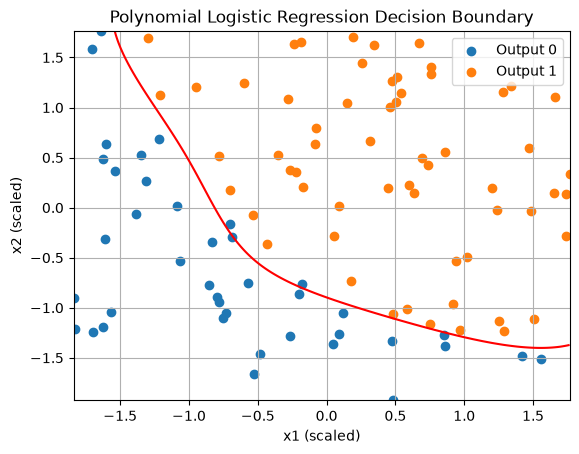

In [25]:
x1_values = np.linspace(X_scaled[:, 0].min(), X_scaled[:, 0].max(), 200)
x2_values = np.linspace(X_scaled[:, 1].min(), X_scaled[:, 1].max(), 200)

xx, yy = np.meshgrid(x1_values, x2_values)

grid = np.column_stack((xx.ravel(), yy.ravel()))
grid_poly = map_feature(grid, degree=6)

probabilities = sigmoid(np.dot(grid_poly, w_poly) + b_poly)
Z = probabilities.reshape(xx.shape)

plt.scatter(X_scaled[y == 0, 0], X_scaled[y == 0, 1], label="Output 0")
plt.scatter(X_scaled[y == 1, 0], X_scaled[y == 1, 1], label="Output 1")

plt.contour(xx, yy, Z, levels=[0.5], colors="red")

plt.xlabel("x1 (scaled)")
plt.ylabel("x2 (scaled)")
plt.title("Polynomial Logistic Regression Decision Boundary")
plt.legend()
plt.grid()
plt.show()

## Prediction and Model Evaluation

Calculate the predicted probabilities and convert them into binary classes using a threshold of 0.5.

Then calculated the confusion matrix, Accuracy, Precision, Recall, and F1-score.

In [26]:
y_poly_prob = sigmoid(np.dot(X_poly, w_poly) + b_poly)
y_poly_pred = (y_poly_prob >= 0.5).astype(int)

prediction_table_poly = pd.DataFrame({
    "Actual Output": y,
    "Predicted Probability": y_poly_prob,
    "Predicted Output": y_poly_pred
})

display(prediction_table_poly.head(20).round(4))

,Actual Output,Predicted Probability,Predicted Output
0,0.0,0.0000,0
1,0.0,0.0000,0
2,0.0,0.0000,0
3,1.0,0.9892,1
4,1.0,0.9668,1
5,0.0,0.0173,0
6,1.0,0.9998,1
7,1.0,0.6061,1
8,1.0,0.9949,1
9,1.0,0.7304,1


In [27]:
TP = np.sum((y == 1) & (y_poly_pred == 1))
TN = np.sum((y == 0) & (y_poly_pred == 0))
FP = np.sum((y == 0) & (y_poly_pred == 1))
FN = np.sum((y == 1) & (y_poly_pred == 0))

conf_matrix_poly = np.array([
    [TN, FP],
    [FN, TP]
])

accuracy_poly = (TP + TN) / len(y) * 100
precision_poly = TP / (TP + FP) if TP + FP > 0 else 0
recall_poly = TP / (TP + FN) if TP + FN > 0 else 0

f1_poly = (
    2 * precision_poly * recall_poly / (precision_poly + recall_poly)
    if precision_poly + recall_poly > 0 else 0
)

print("Confusion Matrix:")
print(conf_matrix_poly)

print("Training Accuracy:", accuracy_poly, "%")
print("Precision:", precision_poly)
print("Recall:", recall_poly)
print("F1 Score:", f1_poly)

Confusion Matrix:
[[38  2]
 [ 0 60]]
Training Accuracy: 98.0 %
Precision: 0.967741935483871
Recall: 1.0
F1 Score: 0.9836065573770492


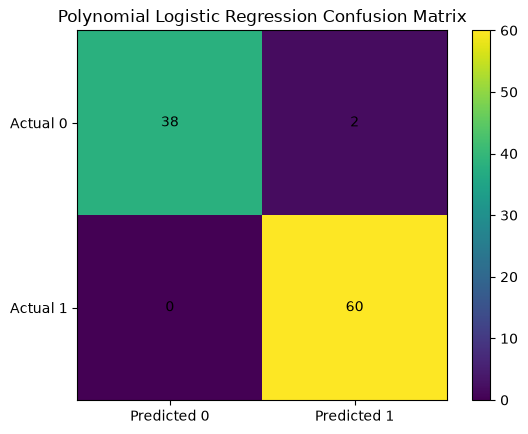

In [28]:
plt.imshow(conf_matrix_poly)
plt.colorbar()

plt.xticks([0, 1], ["Predicted 0", "Predicted 1"])
plt.yticks([0, 1], ["Actual 0", "Actual 1"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, conf_matrix_poly[i, j],
                 ha="center", va="center")

plt.title("Polynomial Logistic Regression Confusion Matrix")
plt.show()